# Session 13 · Advanced Deep Learning Techniques

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hamnakhan123/Diploma-in-Data-Science/blob/main/term-2/03-advanced-data-science-with-python/code/session-13-advanced-deep-learning.ipynb)

Diploma in Data Science · Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run the cells from top to bottom. Every example is self-contained, so you can also run any single cell on its own.

### Example 1 · Basic: transfer learning with a small CNN (pre-train, then fine-tune)

In [1]:
"""Transfer learning in miniature: pre-train on clean digit scans, reuse for noisy 'phone photos' with 5 labels per class."""
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from sklearn.datasets import load_digits
torch.set_num_threads(2)

d = load_digits()
X = F.interpolate(torch.tensor(d.images / 16.0, dtype=torch.float32).unsqueeze(1), size=16, mode="bilinear", align_corners=False)
y = torch.tensor(d.target)
rng = np.random.default_rng(0)
idx = rng.permutation(len(y))
src, tgt = idx[:900], idx[900:]                                    # different images for the two tasks
# Target domain = 'phone photos': lower contrast, background noise and random shifts
gen = torch.Generator().manual_seed(0)
Xt = 0.6 * X + 0.35 * torch.rand(X.shape, generator=gen)
Xt = torch.stack([torch.roll(img, shifts=(int(rng.integers(-2, 3)), int(rng.integers(-2, 3))), dims=(1, 2)) for img in Xt])
few = np.concatenate([rng.choice(tgt[d.target[tgt] == c], 5, replace=False) for c in range(10)])   # only 50 labels
test = np.setdiff1d(tgt, few)

def backbone():
    return nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten())

def train(model, data, idx, epochs, lr, params=None):
    opt = torch.optim.Adam(params if params is not None else model.parameters(), lr=lr)
    for ep in range(epochs):
        perm = rng.permutation(idx)
        for i in range(0, len(perm), 32):
            b = perm[i:i + 32]
            opt.zero_grad(); F.cross_entropy(model(data[b]), y[b]).backward(); opt.step()

def acc(model, data, idx):
    model.eval()
    with torch.no_grad():
        return (model(data[idx]).argmax(1) == y[idx]).float().mean().item()

torch.manual_seed(0)
pre = nn.Sequential(backbone(), nn.Linear(512, 10))
train(pre, X, src, epochs=15, lr=2e-3)                               # source: 900 clean labelled scans
print(f"pre-trained model, clean scans (held out): {acc(pre, X, tgt):.3f}")
print(f"pre-trained model used as-is on noisy photos: {acc(pre, Xt, test):.3f}")

results = {}
torch.manual_seed(1)
scratch = nn.Sequential(backbone(), nn.Linear(512, 10)); train(scratch, Xt, few, 80, 2e-3)
results["from scratch (50 photos)"] = acc(scratch, Xt, test)
torch.manual_seed(1)
fe = nn.Sequential(backbone(), nn.Linear(512, 10)); fe.load_state_dict(pre.state_dict())
for p in fe[0].parameters(): p.requires_grad = False                 # freeze the backbone, retrain the head
train(fe, Xt, few, 80, 2e-3, params=fe[1].parameters())
results["feature extraction (frozen)"] = acc(fe, Xt, test)
torch.manual_seed(1)
ft = nn.Sequential(backbone(), nn.Linear(512, 10)); ft.load_state_dict(pre.state_dict())
train(ft, Xt, few, 80, 3e-4)                                         # small learning rate for all layers
results["fine-tuning (all layers)"] = acc(ft, Xt, test)
for k, v in results.items():
    print(f"{k:<30} accuracy on unseen noisy photos: {v:.3f}")

pre-trained model, clean scans (held out): 0.973
pre-trained model used as-is on noisy photos: 0.525


from scratch (50 photos)       accuracy on unseen noisy photos: 0.451
feature extraction (frozen)    accuracy on unseen noisy photos: 0.590
fine-tuning (all layers)       accuracy on unseen noisy photos: 0.583


### Example 2 · Intermediate: a residual block and why depth needs it

In [2]:
"""Plain deep MLP vs the same depth with residual connections: gradient flow and training loss."""
import torch
from torch import nn
torch.set_num_threads(2)

class Block(nn.Module):
    def __init__(self, width, residual):
        super().__init__()
        self.f = nn.Sequential(nn.Linear(width, width), nn.Tanh(), nn.Linear(width, width))
        self.residual = residual
    def forward(self, x):
        return torch.tanh(self.f(x) + x) if self.residual else torch.tanh(self.f(x))

def make(depth, residual):
    return nn.Sequential(nn.Linear(10, 32), *[Block(32, residual) for _ in range(depth)], nn.Linear(32, 1))

torch.manual_seed(0)
X = torch.randn(512, 10); y = (X[:, :3].sum(1, keepdim=True) > 0).float()
print("depth  type       grad norm at first layer   loss after 200 steps")
for depth in [2, 20, 40]:
    for residual in [False, True]:
        torch.manual_seed(0)
        m = make(depth, residual)
        loss = nn.functional.binary_cross_entropy_with_logits(m(X), y); loss.backward()
        g = m[0].weight.grad.norm().item()
        opt = torch.optim.Adam(m.parameters(), lr=1e-3)
        for _ in range(200):
            opt.zero_grad(); l = nn.functional.binary_cross_entropy_with_logits(m(X), y); l.backward(); opt.step()
        print(f"{depth:>5}  {'residual' if residual else 'plain':<9}  {g:>24.2e}   {l.item():>20.3f}")

depth  type       grad norm at first layer   loss after 200 steps


    2  plain                      1.54e-02                  0.004


    2  residual                   1.77e-01                  0.005


   20  plain                      1.20e-11                  0.692


   20  residual                   7.04e-02                  0.003


   40  plain                      2.75e-21                  0.692


   40  residual                   4.07e-02                  0.035


### Example 3 · Intermediate: a GAN that learns to draw digits

step    0: loss D 1.482  loss G 0.653  D(real) 0.50  D(fake) 0.52


step  300: loss D 1.216  loss G 0.994  D(real) 0.51  D(fake) 0.37


step 1000: loss D 1.239  loss G 0.949  D(real) 0.51  D(fake) 0.39


step 3000: loss D 1.314  loss G 0.940  D(real) 0.47  D(fake) 0.43


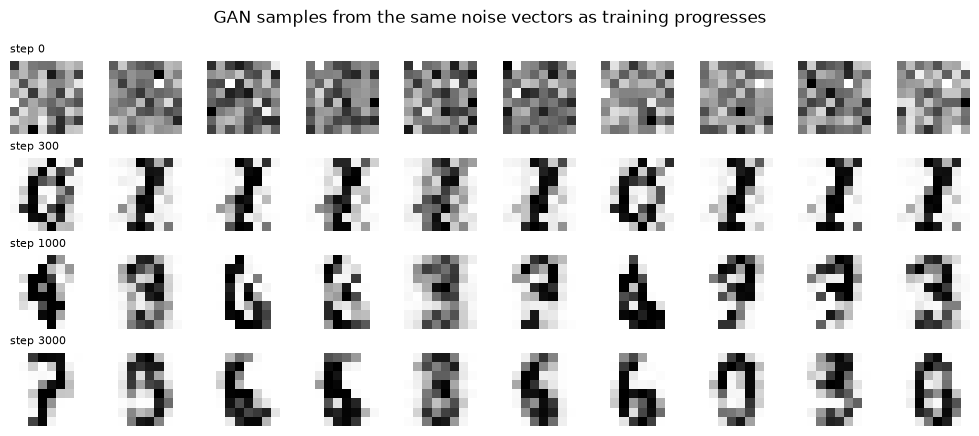

In [3]:
"""A small fully connected GAN trained on 8x8 digit images; saves a grid of generated samples over training."""
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
torch.manual_seed(0); torch.set_num_threads(2)

real = torch.tensor(load_digits().images.reshape(-1, 64) / 8.0 - 1.0, dtype=torch.float32)   # scale to [-1, 1]
Z = 16
G = nn.Sequential(nn.Linear(Z, 128), nn.LeakyReLU(0.2), nn.Linear(128, 128), nn.LeakyReLU(0.2), nn.Linear(128, 64), nn.Tanh())
D = nn.Sequential(nn.Linear(64, 128), nn.LeakyReLU(0.2), nn.Dropout(0.3), nn.Linear(128, 1))
optG = torch.optim.Adam(G.parameters(), lr=1e-3, betas=(0.5, 0.999))
optD = torch.optim.Adam(D.parameters(), lr=1e-3, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()
fixed_z = torch.randn(10, Z)
snapshots = {}
for step in range(3001):
    xb = real[torch.randint(0, len(real), (64,))]
    fake = G(torch.randn(64, Z))
    # 1) discriminator: real -> 1 (smoothed to 0.9), fake -> 0
    optD.zero_grad()
    lossD = bce(D(xb), torch.full((64, 1), 0.9)) + bce(D(fake.detach()), torch.zeros(64, 1))
    lossD.backward(); optD.step()
    # 2) generator: wants D to say 'real' for fakes
    optG.zero_grad()
    lossG = bce(D(fake), torch.ones(64, 1))
    lossG.backward(); optG.step()
    if step in (0, 300, 1000, 3000):
        with torch.no_grad():
            snapshots[step] = G(fixed_z).numpy()
            dr, df = torch.sigmoid(D(xb)).mean().item(), torch.sigmoid(D(fake)).mean().item()
        print(f"step {step:>4}: loss D {lossD.item():.3f}  loss G {lossG.item():.3f}  D(real) {dr:.2f}  D(fake) {df:.2f}")

fig, ax = plt.subplots(4, 10, figsize=(10, 4.4))
for r, (step, imgs) in enumerate(snapshots.items()):
    for c in range(10):
        ax[r, c].imshow(imgs[c].reshape(8, 8), cmap="gray_r"); ax[r, c].axis("off")
    ax[r, 0].set_title(f"step {step}", fontsize=8, loc="left")
fig.suptitle("GAN samples from the same noise vectors as training progresses")
fig.tight_layout(); fig.savefig("session-13_gan_samples.png", dpi=100); plt.show()

### Example 4 · Intermediate: attention from scratch and multi-head attention in PyTorch

'he' attends most to: he (0.48), rider (0.20), the (0.06)
'fast' attends most to: fast (0.30), delivered (0.21), biryani (0.10)
each row of weights sums to 1: True
PyTorch multi-head output: (1, 9, 8) | averaged attention weights: (1, 9, 9)


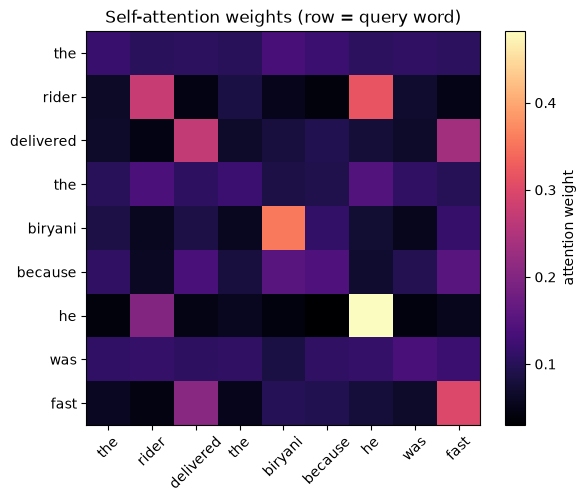

In [4]:
"""Scaled dot-product attention in NumPy on a toy sentence, then PyTorch MultiheadAttention shapes."""
import numpy as np
import torch
import matplotlib.pyplot as plt

words = ["the", "rider", "delivered", "the", "biryani", "because", "he", "was", "fast"]
rng = np.random.default_rng(0)
d = 8
# Hand-made embeddings: 'he' is similar to 'rider'; 'fast' is similar to 'delivered'
E = rng.normal(0, .3, (len(words), d))
E[1] += [2, 0, 0, 0, 0, 0, 0, 0]; E[6] += [2, 0, 0, 0, 0, 0, 0, 0]          # rider ~ he
E[2] += [0, 2, 0, 0, 0, 0, 0, 0]; E[8] += [0, 2, 0, 0, 0, 0, 0, 0]          # delivered ~ fast
E[4] += [0, 0, 2, 0, 0, 0, 0, 0]

def attention(Q, K, V):
    scores = Q @ K.T / np.sqrt(Q.shape[1])
    w = np.exp(scores - scores.max(axis=1, keepdims=True)); w /= w.sum(axis=1, keepdims=True)
    return w @ V, w

out, W = attention(E, E, E)                       # self-attention with identity projections
for i in [6, 8]:
    top = np.argsort(-W[i])[:3]
    print(f"'{words[i]}' attends most to: " + ", ".join(f"{words[j]} ({W[i, j]:.2f})" for j in top))
print("each row of weights sums to 1:", np.allclose(W.sum(1), 1))

mha = torch.nn.MultiheadAttention(embed_dim=8, num_heads=2, batch_first=True)
x = torch.tensor(E, dtype=torch.float32).unsqueeze(0)          # (batch 1, 9 tokens, 8 dims)
y, w = mha(x, x, x)
print("PyTorch multi-head output:", tuple(y.shape), "| averaged attention weights:", tuple(w.shape))

plt.figure(figsize=(6, 5))
plt.imshow(W, cmap="magma"); plt.colorbar(label="attention weight")
plt.xticks(range(len(words)), words, rotation=45); plt.yticks(range(len(words)), words)
plt.title("Self-attention weights (row = query word)")
plt.tight_layout(); plt.savefig("session-13_attention_heatmap.png", dpi=110); plt.show()

### Example 5 · Advanced: style transfer's key ingredient, the Gram matrix

In [5]:
"""Content vs style: feature maps differ when layout changes, Gram matrices (texture statistics) stay similar."""
import numpy as np
import torch
from torch import nn
torch.manual_seed(0)

def stripes(h=32, w=32, angle=0.0, freq=6, shift=0):
    yy, xx = np.mgrid[0:h, 0:w]
    return np.sin(freq * 2 * np.pi * (np.cos(angle) * (xx + shift) + np.sin(angle) * yy) / w)

def dots(h=32, w=32, shift=0):
    yy, xx = np.mgrid[0:h, 0:w]
    return np.sin(2 * np.pi * (xx + shift) / 8) * np.sin(2 * np.pi * yy / 8)

imgs = {"stripes": stripes(), "stripes moved": stripes(shift=3), "dots": dots()}
cnn = nn.Sequential(nn.Conv2d(1, 16, 5, padding=2), nn.ReLU(), nn.Conv2d(16, 16, 3, padding=1), nn.ReLU())

def features(img):
    with torch.no_grad():
        return cnn(torch.tensor(img, dtype=torch.float32)[None, None])[0]        # (C, H, W)

def gram(F):
    C = F.shape[0]; Fm = F.reshape(C, -1)
    return Fm @ Fm.T / Fm.shape[1]                                                # (C, C): which features co-occur

feats = {k: features(v) for k, v in imgs.items()}
grams = {k: gram(f) for k, f in feats.items()}
def dist(a, b): return (a - b).pow(2).mean().sqrt().item()
print(f"{'pair':<28}{'content distance':>18}{'style (Gram) distance':>24}")
for a, b in [("stripes", "stripes moved"), ("stripes", "dots")]:
    print(f"{a + ' vs ' + b:<28}{dist(feats[a], feats[b]):>18.4f}{dist(grams[a], grams[b]):>24.4f}")

pair                          content distance   style (Gram) distance
stripes vs stripes moved                0.0822                  0.0007
stripes vs dots                         0.0758                  0.0025


### 🏙️ Real-life data problem: a Deep Q-Network for a smart thermostat

In [6]:
"""Real-life problem: DQN controller for office air-conditioning vs a rule-based thermostat."""
import random
from collections import deque
import numpy as np
import torch
from torch import nn
torch.manual_seed(0); random.seed(0); torch.set_num_threads(2)
rng = np.random.default_rng(0)

ACTIONS = ["off", "eco", "boost"]
COOL = [0.0, 1.0, 2.2]           # degrees removed per 15 min
POWER = [0.0, 1.0, 2.6]          # kWh per 15 min
STEPS = 40                       # 8 am to 6 pm

def outdoor(t):                  # hot afternoon peak
    return 31 + 7 * np.sin(np.pi * t / STEPS)

class Office:
    def reset(self):
        self.t, self.temp = 0, 27.0 + rng.normal(0, .5)
        return self.state()
    def state(self):
        return np.array([(self.temp - 24) / 4, (outdoor(self.t) - 32) / 5, self.t / STEPS], dtype=np.float32)
    def step(self, a):
        drift = 0.12 * (outdoor(self.t) - self.temp) + 0.25              # heat from outside + people/computers
        self.temp += drift - COOL[a] + rng.normal(0, .1)
        self.t += 1
        discomfort = max(0, abs(self.temp - 24) - 1)                      # within 23-25 °C is fine
        reward = -(2.0 * discomfort + 0.4 * POWER[a])
        return self.state(), reward, self.t >= STEPS, discomfort, POWER[a]

def qnet():
    return nn.Sequential(nn.Linear(3, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 3))

env, online, target = Office(), qnet(), qnet()
target.load_state_dict(online.state_dict())
opt = torch.optim.Adam(online.parameters(), lr=1e-3)
buffer, gamma, batch = deque(maxlen=20000), 0.95, 64
for episode in range(300):
    s, done, eps = env.reset(), False, max(0.05, 1 - episode / 150)
    while not done:
        if random.random() < eps:
            a = random.randrange(3)
        else:
            with torch.no_grad():
                a = int(online(torch.tensor(s)).argmax())
        s2, r, done, _, _ = env.step(a)
        buffer.append((s, a, r, s2, done)); s = s2
        if len(buffer) >= 500:
            S, A, R, S2, Dn = map(np.array, zip(*random.sample(buffer, batch)))
            S, S2 = torch.tensor(S), torch.tensor(S2)
            q = online(S).gather(1, torch.tensor(A).unsqueeze(1)).squeeze(1)
            with torch.no_grad():
                y = torch.tensor(R, dtype=torch.float32) + gamma * target(S2).max(1).values * (1 - torch.tensor(Dn, dtype=torch.float32))
            loss = nn.functional.smooth_l1_loss(q, y)
            opt.zero_grad(); loss.backward(); opt.step()
    if episode % 10 == 0:
        target.load_state_dict(online.state_dict())          # refresh the target network

def evaluate(policy, days=30):
    tot_r = tot_d = tot_e = 0
    for _ in range(days):
        s, done = env.reset(), False
        while not done:
            s, r, done, disc, kwh = env.step(policy(s))
            tot_r += r; tot_d += disc; tot_e += kwh
    return tot_r / days, tot_d / days, tot_e / days

def rule(s):                                   # classic thermostat: boost above 25.5, eco above 24.5, else off
    temp = s[0] * 4 + 24
    return 2 if temp > 25.5 else 1 if temp > 24.5 else 0
def dqn(s):
    with torch.no_grad():
        return int(online(torch.tensor(s)).argmax())

print(f"{'controller':<22}{'reward/day':>11}{'discomfort/day':>16}{'energy kWh/day':>16}")
for name, pol in [("rule-based thermostat", rule), ("always eco", lambda s: 1), ("DQN agent", dqn)]:
    r, d, e = evaluate(pol)
    print(f"{name:<22}{r:>11.1f}{d:>16.2f}{e:>16.1f}")

env.reset(); env.temp = 27.0
plan = []
s = env.state()
for t in range(STEPS):
    a = dqn(s); plan.append(ACTIONS[a][0].upper())
    s, *_ = env.step(a)
print("\nDQN actions over the day (O=off, E=eco, B=boost):", "".join(plan))

controller             reward/day  discomfort/day  energy kWh/day
rule-based thermostat       -61.0           17.19            66.5
always eco                 -339.7          161.85            40.0
DQN agent                   -31.0            0.57            74.5

DQN actions over the day (O=off, E=eco, B=boost): BBBEEEBEBEBEBBEBBBEBBEBBEBBEBBEBEBEEEEEB


### 🧩 Mini project: a tiny transformer encoder classifier

In [7]:
"""Mini project: a one-layer transformer encoder (self-attention) vs bag of words on messages where negation flips meaning."""
import numpy as np
import torch
from torch import nn
torch.manual_seed(0); torch.set_num_threads(2)
rng = np.random.default_rng(0)

subjects = ["please", "kindly", "i want to", "can you", "we need to", "urgent"]
items = ["my order", "the biryani", "order 4521", "the pizza", "this delivery", "my parcel"]
STOP, GO = ["cancel", "stop", "hold"], ["deliver", "send", "dispatch"]
def message():
    stop_verb = rng.random() < .5
    neg = rng.random() < .5
    verb = rng.choice(STOP if stop_verb else GO)
    text = f"{rng.choice(subjects)} {'do not ' if neg else ''}{verb} {rng.choice(items)}"
    # the customer wants the order STOPPED: 'cancel' or 'do not deliver' -> 1; 'deliver' or 'do not cancel' -> 0
    return text, int(stop_verb != neg)

data = [message() for _ in range(3000)]
vocab = {"<pad>": 0}
for t, _ in data:
    for w in t.split(): vocab.setdefault(w, len(vocab))
L = 10
enc = lambda t: ([vocab.get(w, 0) for w in t.split()] + [0] * L)[:L]
X = torch.tensor([enc(t) for t, _ in data]); Y = torch.tensor([y for _, y in data], dtype=torch.float32)
tr, te = slice(0, 2500), slice(2500, 3000)

class TinyTransformer(nn.Module):
    def __init__(self, V, d=32):
        super().__init__()
        self.emb = nn.Embedding(V, d, padding_idx=0)
        self.pos = nn.Parameter(torch.randn(L, d) * .1)              # learned positional encoding
        self.enc = nn.TransformerEncoder(nn.TransformerEncoderLayer(d, nhead=4, dim_feedforward=64, batch_first=True), 1)
        self.out = nn.Linear(d, 1)
    def forward(self, x):
        h = self.enc(self.emb(x) + self.pos, src_key_padding_mask=(x == 0))
        mask = (x != 0).unsqueeze(2).float()
        return self.out((h * mask).sum(1) / mask.sum(1)).squeeze(1)

class BagOfWords(nn.Module):                                          # baseline: ignores order and interactions
    def __init__(self, V, d=32):
        super().__init__(); self.emb = nn.EmbeddingBag(V, d, padding_idx=0); self.out = nn.Linear(d, 1)
    def forward(self, x): return self.out(self.emb(x)).squeeze(1)

for name, model in [("bag of words", BagOfWords(len(vocab))), ("tiny transformer", TinyTransformer(len(vocab)))]:
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    for epoch in range(15):
        model.train(); perm = torch.randperm(2500)
        for i in range(0, 2500, 64):
            b = perm[i:i + 64]
            opt.zero_grad(); nn.functional.binary_cross_entropy_with_logits(model(X[b]), Y[b]).backward(); opt.step()
    model.eval()
    with torch.no_grad():
        acc = ((model(X[te]) > 0).float() == Y[te]).float().mean().item()
    print(f"{name:<17} test accuracy: {acc:.3f}")

tests = ["please cancel my order", "please do not cancel my order", "do not deliver the pizza", "kindly send my parcel"]
with torch.no_grad():
    p = torch.sigmoid(model(torch.tensor([enc(t) for t in tests])))
for t, v in zip(tests, p):
    print(f"P(stop order) = {v:.2f}  '{t}'")

bag of words      test accuracy: 0.532


tiny transformer  test accuracy: 1.000
P(stop order) = 1.00  'please cancel my order'
P(stop order) = 0.00  'please do not cancel my order'
P(stop order) = 1.00  'do not deliver the pizza'
P(stop order) = 0.00  'kindly send my parcel'
